# Stage 2A-1：実際にランダムに並べた混合交通を、アルゴリズムは 1-pipe と判定できるか

- 正解：論文形の名目速度関数、セットP（論文 Table 4/5 の値。どこでも s < 0）
- 見た目：1車線の円環に車とトラックをランダムに並べた混合交通 → **見た目は 1-pipe**
- Stage 1 との違い：トラックの塊の数 m を平均値ではなく、**実際に並べたときの整数**にする
- アルゴリズム：Stage 1 で検証済みの src（whole_pipeline）の Eq.7 と Eq.11 をそのまま使う
- 交通条件は NGSIM に合わせず、一般的に振る（全体の密度 × トラックの割合 × 区間の長さ）

流れ：台数を決める → ランダムに並べて m を数える → 円環の定常速度 v（= 観測速度）→ Eq.7 で u* → Eq.11 で判定（ε を変える）→ 集計

In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

ROOT = Path(os.path.abspath("../.."))   # notebooks/check → notebooks → ルート
sys.path.append(str(ROOT))

from src.ring_equilibrium import make_paper_nominal, pair_counts, lane_speed, v_range, CAR, TRUCK
from src.whole_pipeline import (solve_1pipe_speed, compute_min_road_share,
                                compute_cooperation_surplus, classify_traffic_regime)

KM_TO_MILE = 1.60934
OUT = ROOT / "results" / "stage2A1_2026-11-09"
OUT.mkdir(parents=True, exist_ok=True)

## 0. パラメータと実験条件

In [2]:
# 論文 Table 4（km/h, veh/km に換算）と Table 5：セットP
CAR_PARAMS = {'ub': 7.93 * KM_TO_MILE, 'uf': 73.55 * KM_TO_MILE, 'rhoc': 20.40 / KM_TO_MILE,
              'theta1': 8.0387 / KM_TO_MILE, 'theta2': 0.2309}
TRUCK_PARAMS = {'uf': 42.55 * KM_TO_MILE, 'rhoc': 41.74 / KM_TO_MILE}
A2, B1 = 0.4528, 2.5996

# 正解側の名目速度関数（円環の定常速度を解くのに使う）
NOMINAL = make_paper_nominal(CAR_PARAMS, TRUCK_PARAMS, A2, B1)

# 実験条件（NGSIM には合わせず、一般的に振る）
RHO_TOT = [20, 40, 60, 80, 100]            # 全体の密度 (veh/km/lane)
P2_LIST = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5]       # トラックの割合（台数ベース）
L_LIST  = [250, 500, 1000, 2000]     # 区間（円環）の長さ (m)。544 m は NGSIM の区間長
EPS_LIST = [1e-6, 0.5, 1.0, 2.0]      # ε (km/h)。1e-6 は ε=0 の実装上の値、2 は Chen の値
N_SHUFFLE = 1000                       # 条件ごとのシャッフル回数
SEED = 0

# 名目速度関数が使える速度の範囲（混合の定常速度はこの中にないといけない）
V_LO = max(v_range(NOMINAL, i, j)[0] for i, j in [(1, 1), (1, 2), (2, 2), (2, 1)])
V_HI = min(v_range(NOMINAL, i, j)[1] for i, j in [(1, 1), (1, 2), (2, 2), (2, 1)])
print(f"使える速度の範囲: {V_LO:.2f} 〜 {V_HI:.2f} km/h")

使える速度の範囲: 12.76 〜 68.48 km/h


## 1. 部品
- `count_truck_blocks`：円環に並べた車列から m（トラックの塊の数 ＝ 車の直後にトラックが来る場所の数）を数える
- `sample_m`：ランダムに N_SHUFFLE 回並べて m を集める
- `ring_speed`：整数の m で円環の定常速度 v を解く（Σ n_ij·h_ij(v) = L）

定常状態の速度は並びの細かい順番には関係なく **m だけで決まる**ので、速度は m の種類ごとに1回だけ解けばよい

In [3]:
def count_truck_blocks(order):
    """
    order: 0=車, 1=トラック の配列（円環なので最後の車の次は最初の車）。形は (シャッフル回数, 台数)
    m = 「自分がトラックで、すぐ後ろ（1つ前の位置）が車」の数 ＝ C-T ペアの数 ＝ トラックの塊の数
    """
    behind = np.roll(order, 1, axis=1)          # 1つ前の位置の車種
    return np.sum((order == 1) & (behind == 0), axis=1)#自分が1で一つ前が0のペアの和


def sample_m(n1, n2, n_shuffle, rng):
    """n1 台の車と n2 台のトラックを円環にランダムに並べて、m を n_shuffle 回集める"""
    base = np.array([0] * n1 + [1] * n2)#n1個の0とn2個の1を並べた配列
    orders = rng.permuted(np.tile(base, (n_shuffle, 1)), axis=1)#baseをnshuffle行に複製→各行の中身を別々にシャッフル
    return count_truck_blocks(orders)#mの数を数えて返す


def ring_speed(n1, n2, m, L):
    """整数の台数・m で、1車線の円環の定常速度 v (km/h) を解く。解けない・上限に張り付く場合は NaN"""
    v = lane_speed(NOMINAL, pair_counts(n1, n2, int(m)), L)#Σ n_ij·h_ij(v) = L を v について解く
    if not np.isfinite(v) or v >= V_HI - 1e-9:
        return np.nan
    return v


# 確認：車4台・トラック2台を並べたときの m の分布
rng_test = np.random.default_rng(1)#乱数　シード
print(pd.Series(sample_m(100, 50, 10000, rng_test)).value_counts(normalize=True).sort_index())

24    0.0005
25    0.0014
26    0.0034
27    0.0085
28    0.0190
29    0.0358
30    0.0630
31    0.0935
32    0.1156
33    0.1400
34    0.1471
35    0.1330
36    0.0998
37    0.0675
38    0.0368
39    0.0223
40    0.0080
41    0.0039
42    0.0006
43    0.0002
46    0.0001
Name: proportion, dtype: float64


## 2. 条件ごとに並べて、正解の速度（観測速度）を作る
- 台数は n1 = round(ρ·(1−P2)·L), n2 = round(ρ·P2·L)。トラックが 0 台になる条件は飛ばす
- アルゴリズムに渡す密度は整数の台数から計算し直す（ρ_i = n_i / L）
- 比較のために、ランダム混合の平均 m̄ = n1·n2/N（Stage 1 と同じ前提）での速度 v_avg も出す

In [4]:
rng = np.random.default_rng(SEED)#乱数シード値を設定しているため何回やっても同じ値
rows = []          # シャッフル1回 = 1行（＝スナップショット1枚）
conds = []         # 条件ごとの情報

for L in L_LIST:#円環の長さ（観測区間の長さ　データのばらつきに影響）
    for rho in RHO_TOT:#全体の密度
        for P2 in P2_LIST:#トラックの割合
            n1 = int(round(rho * (1 - P2) * L / 1000))#車の台数 = 密度 * 車の割合 * 区間長（km） = ρ1 * L　整数に丸めて台数にする
            n2 = int(round(rho * P2 * L / 1000))#車の台数 = 密度 * 車の割合 * 区間長（km） = ρ2 * L　整数に丸めて台数にする
            if n1 == 0 or n2 == 0:  # どちらかが0台なら混合にならないので飛ばす
                continue
            rho1, rho2 = n1 / (L / 1000), n2 / (L / 1000)# 整数にした台数から密度を計算し直す　veh/km/lane

            m_samples = sample_m(n1, n2, N_SHUFFLE, rng)#n1,n2の車両数で並べ変えてmを数えて速度を計算
            v_of_m = {m: ring_speed(n1, n2, m, L) for m in np.unique(m_samples)}#mの種類ごとに速度を計算して辞書に格納

            # 平均の m（連続値）での速度 = Stage 1 の前提 m=n1*n2/(n1+n2) での速度 eq7
            v_avg = lane_speed(NOMINAL, pair_counts(n1, n2, None), L)

            #記録　条件1つにつき1行
            conds.append({'L': L, 'rho_tot': rho, 'P2': P2, 'n1': n1, 'n2': n2,
                          'rho1': rho1, 'rho2': rho2, 'm_bar': n1 * n2 / (n1 + n2), 'v_avg': v_avg,
                          'n_m_kinds': len(v_of_m)})
            for k, m in enumerate(m_samples):#シャッフル1回につき1行
                v = v_of_m[m]
                rows.append({'L': L, 'rho_tot': rho, 'P2': P2, 'shuffle': k,
                             'rho1': rho1, 'rho2': rho2, 'm': m,
                             'u1_obs': v, 'u2_obs': v})      # 混合なので全員が同じ速度

df_obs = pd.DataFrame(rows)#スナップショットの表
df_cond = pd.DataFrame(conds)#条件の表
print(f"条件 {len(df_cond)} 通り、スナップショット {len(df_obs):,} 枚")
print(f"速度が範囲外（NaN）のスナップショット: {df_obs['u1_obs'].isna().sum():,} 枚")
df_cond

#トラックの台数が 20 × 0.05 × 0.5 = 0.5 台になり、round で 0 に丸められたため、continue で飛ばされた？

条件 116 通り、スナップショット 116,000 枚
速度が範囲外（NaN）のスナップショット: 3,847 枚


,L,rho_tot,P2,n1,n2,rho1,rho2,m_bar,v_avg,n_m_kinds
0,250,20,0.2,4,1,16.0,4.0,0.800000,55.718718,1
1,250,20,0.3,4,2,16.0,8.0,1.333333,44.415589,2
2,250,20,0.4,3,2,12.0,8.0,1.200000,47.052408,2
3,250,20,0.5,2,2,8.0,8.0,1.000000,49.068653,2
4,250,40,0.1,9,1,36.0,4.0,0.900000,36.199851,1
...,...,...,...,...,...,...,...,...,...,...
111,2000,100,0.1,180,20,90.0,10.0,18.000000,13.784226,7
112,2000,100,0.2,160,40,80.0,20.0,32.000000,13.220104,17
113,2000,100,0.3,140,60,70.0,30.0,42.000000,12.892898,20
114,2000,100,0.4,120,80,60.0,40.0,48.000000,12.772789,23


In [5]:
display(df_cond[df_cond['v_avg'].isna()])              # v_avg が NaN の条件
display(df_cond[df_cond['v_avg'] >= V_HI - 1e-6])      # 上限に張り付いた条件

nan = df_obs[df_obs['u1_obs'].isna()]
print(nan.groupby(['L', 'rho_tot', 'P2']).size())          # どの条件に何枚あるか
print(nan.groupby(['L', 'rho_tot', 'P2'])['m'].unique())   # NaN になった m の値

,L,rho_tot,P2,n1,n2,rho1,rho2,m_bar,v_avg,n_m_kinds
26,250,100,0.5,12,12,48.0,48.0,6.0,NaN,8
55,500,100,0.5,25,25,50.0,50.0,12.5,NaN,11
85,1000,100,0.5,50,50,50.0,50.0,25.0,NaN,17
115,2000,100,0.5,100,100,50.0,50.0,50.0,NaN,24


,L,rho_tot,P2,n1,n2,rho1,rho2,m_bar,v_avg,n_m_kinds


L     rho_tot  P2 
250   100      0.4       3
               0.5     844
500   100      0.4       1
               0.5     999
1000  100      0.5    1000
2000  100      0.5    1000
dtype: int64
L     rho_tot  P2 
250   100      0.4                                               [2, 3]
               0.5                                      [6, 5, 7, 4, 3]
500   100      0.4                                                  [7]
               0.5               [10, 12, 16, 13, 14, 15, 11, 17, 9, 8]
1000  100      0.5    [27, 26, 21, 23, 20, 28, 25, 29, 24, 30, 22, 3...
2000  100      0.5    [51, 55, 54, 50, 53, 45, 46, 49, 47, 56, 44, 5...
Name: m, dtype: object


In [6]:
df_cond.head(10)

,L,rho_tot,P2,n1,n2,rho1,rho2,m_bar,v_avg,n_m_kinds
0,250,20,0.20,4,1,16.0,4.0,0.800000,55.718718,1
1,250,20,0.30,4,2,16.0,8.0,1.333333,44.415589,2
2,250,20,0.40,3,2,12.0,8.0,1.200000,47.052408,2
3,250,20,0.50,2,2,8.0,8.0,1.000000,49.068653,2
4,250,40,0.10,9,1,36.0,4.0,0.900000,36.199851,1
5,250,40,0.20,8,2,32.0,8.0,1.600000,31.684192,2
6,250,40,0.30,7,3,28.0,12.0,2.100000,28.205205,3
7,250,40,0.40,6,4,24.0,16.0,2.400000,25.403302,4
8,250,40,0.50,5,5,20.0,20.0,2.500000,23.072599,5
9,250,60,0.05,14,1,56.0,4.0,0.933333,22.473463,1


## 3. アルゴリズムを流す（src をそのまま使う）
u* は (ρ1, ρ2) だけで決まるので、条件ごとに1回解く

In [7]:
# Step 3a: u*（印刷版 Eq.7）を条件ごとに解く　srcの関数を使う＋rhoと関数形だけを入力として計算
#df_cond:条件が入っている表
df_cond['u_1pipe'] = [solve_1pipe_speed(r['rho1'], r['rho2'], CAR_PARAMS, TRUCK_PARAMS, A2, B1,
                                        scaling='printed')
                      for _, r in df_cond.iterrows()]
df_cond['v_avg_minus_ustar'] = df_cond['v_avg'] - df_cond['u_1pipe']   # Stage 1 の前提なら 0 のはず

df = df_obs.merge(df_cond[['L', 'rho_tot', 'P2', 'u_1pipe']], on=['L', 'rho_tot', 'P2'])#表を結合
df = compute_min_road_share(df, CAR_PARAMS, TRUCK_PARAMS)     # Step 3b　最小道路シェア
df = compute_cooperation_surplus(df)                          # Step 3c　協力余剰
df['dv'] = df['u1_obs'] - df['u_1pipe']                       # 観測速度 − u*

# Step 4: ε ごとに判定
regimes = {}
for eps in EPS_LIST:
    regimes[eps] = classify_traffic_regime(df, eps_kmh=eps)['regime']

print(f"\nv_avg − u* の最大値（Stage 1 の前提では 0 のはず）: {df_cond['v_avg_minus_ustar'].abs().max():.1e} km/h")
print(f"s の最大値（セットP なので負のはず）: {df['s'].max():.4f}")

最小道路占有を計算: 116,000スナップショット中、116,000件で計算完了


協力余剰sを計算: 116,000スナップショット中、116,000件で計算完了（うちs>0: 0件）
交通状態を判定(eps: 車 0.00, トラック 0.00 km/h): 判定対象 112,153件 (対象外 undefined: 3,847件)
      2-pipe: 69,674件 (62.12%)
      1-pipe: 6,652件 (5.93%)
      non-NE: 35,827件 (31.94%)
  Pcoop = 62.12% (論文: 13.83%)
  平均s: 2-pipe = -0.0824, 1-pipe = -0.1032 (論文: 0.15, 0.11)
交通状態を判定(eps: 車 0.50, トラック 0.50 km/h): 判定対象 112,153件 (対象外 undefined: 3,847件)
      2-pipe: 11,180件 (9.97%)
      1-pipe: 96,346件 (85.91%)
      non-NE: 4,627件 (4.13%)
  Pcoop = 9.97% (論文: 13.83%)


  平均s: 2-pipe = -0.2030, 1-pipe = -0.0657 (論文: 0.15, 0.11)
交通状態を判定(eps: 車 1.00, トラック 1.00 km/h): 判定対象 112,153件 (対象外 undefined: 3,847件)
      2-pipe: 5,799件 (5.17%)
      1-pipe: 105,178件 (93.78%)
      non-NE: 1,176件 (1.05%)
  Pcoop = 5.17% (論文: 13.83%)
  平均s: 2-pipe = -0.1889, 1-pipe = -0.0757 (論文: 0.15, 0.11)
交通状態を判定(eps: 車 2.00, トラック 2.00 km/h): 判定対象 112,153件 (対象外 undefined: 3,847件)
      2-pipe: 2,208件 (1.97%)
      1-pipe: 109,665件 (97.78%)
      non-NE: 280件 (0.25%)
  Pcoop = 1.97% (論文: 13.83%)
  平均s: 2-pipe = -0.1528, 1-pipe = -0.0812 (論文: 0.15, 0.11)

v_avg − u* の最大値（Stage 1 の前提では 0 のはず）: 5.0e-13 km/h
s の最大値（セットP なので負のはず）: -0.0074


## 4. 集計
- `dv_mean`：観測速度 − u* の平均（台数が整数であることによる偏り）
- `dv_std`：そのばらつき（並び方のばらつき）
- `dv_absmax`：|観測速度 − u*| の最大
- `P1pipe_eps`：見た目どおり 1-pipe と判定された割合（ε ごと）。残りは 2-pipe か non-NE
- 割合の分母は**判定対象（undefined 以外）**。速度が解けない（名目速度関数の範囲外）スナップショットは undefined として外す
- `P_undef`：undefined の割合（ε によらない）。全部 undefined の条件では P1pipe などは NaN

In [8]:
keys = ['L', 'rho_tot', 'P2']
summary = df.groupby(keys).agg(dv_mean=('dv', 'mean'), dv_std=('dv', 'std'),
                               dv_absmax=('dv', lambda x: x.abs().max())).reset_index()
summary = df_cond[keys + ['n1', 'n2', 'm_bar', 'n_m_kinds', 'u_1pipe']].merge(summary, on=keys)

# 速度が解けなかった（undefined）スナップショットの割合。undefined かどうかは ε によらない
undef = (regimes[EPS_LIST[0]] == 'undefined').groupby([df[k] for k in keys]).mean().rename('P_undef')
summary = summary.merge(undef.reset_index(), on=keys)

#ε ごとに判定結果を集計（割合の分母は判定対象 = undefined 以外。全部 undefined の条件は NaN）
for eps in EPS_LIST:
    r = regimes[eps]
    judged = r != 'undefined'
    tab = pd.DataFrame({'1-pipe': r == '1-pipe', '2-pipe': r == '2-pipe', 'non-NE': r == 'non-NE'})[judged]
    tab[keys] = df.loc[judged, keys]
    g = tab.groupby(keys)[['1-pipe', '2-pipe', 'non-NE']].mean().reset_index()#その判定になった割合
    g = g.rename(columns={'1-pipe': f'P1pipe_{eps:g}', '2-pipe': f'P2pipe_{eps:g}', 'non-NE': f'PnonNE_{eps:g}'})#列名
    summary = summary.merge(g, on=keys, how='left')

summary.to_csv(OUT / "stage2A1_summary.csv", index=False, encoding='utf-8-sig')
pd.set_option('display.max_columns', 40)
summary[keys + ['n1', 'n2', 'u_1pipe', 'P_undef', 'dv_mean', 'dv_std', 'dv_absmax'] + [f'P1pipe_{e:g}' for e in EPS_LIST]].round(3)

,L,rho_tot,P2,n1,n2,u_1pipe,P_undef,dv_mean,dv_std,dv_absmax,P1pipe_1e-06,P1pipe_0.5,P1pipe_1,P1pipe_2
0,250,20,0.2,4,1,55.719,0.0,1.582,0.000,1.582,0.000,0.000,0.000,1.000
1,250,20,0.3,4,2,44.416,0.0,0.990,1.571,2.282,0.000,0.000,0.404,0.404
2,250,20,0.4,3,2,47.052,0.0,1.175,1.881,3.139,0.000,0.000,0.522,0.522
3,250,20,0.5,2,2,49.069,0.0,1.416,1.965,4.141,0.658,0.658,0.658,0.658
4,250,40,0.1,9,1,36.200,0.0,0.187,0.000,0.187,0.000,1.000,1.000,1.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,2000,100,0.1,180,20,13.784,0.0,0.001,0.015,0.048,0.306,1.000,1.000,1.000
112,2000,100,0.2,160,40,13.220,0.0,0.001,0.021,0.080,0.162,1.000,1.000,1.000
113,2000,100,0.3,140,60,12.893,0.0,0.001,0.015,0.054,0.132,1.000,1.000,1.000
114,2000,100,0.4,120,80,12.773,0.0,0.001,0.004,0.016,0.112,1.000,1.000,1.000


## 5. 図：1-pipe と判定された割合（ε ごと、区間の長さごと）

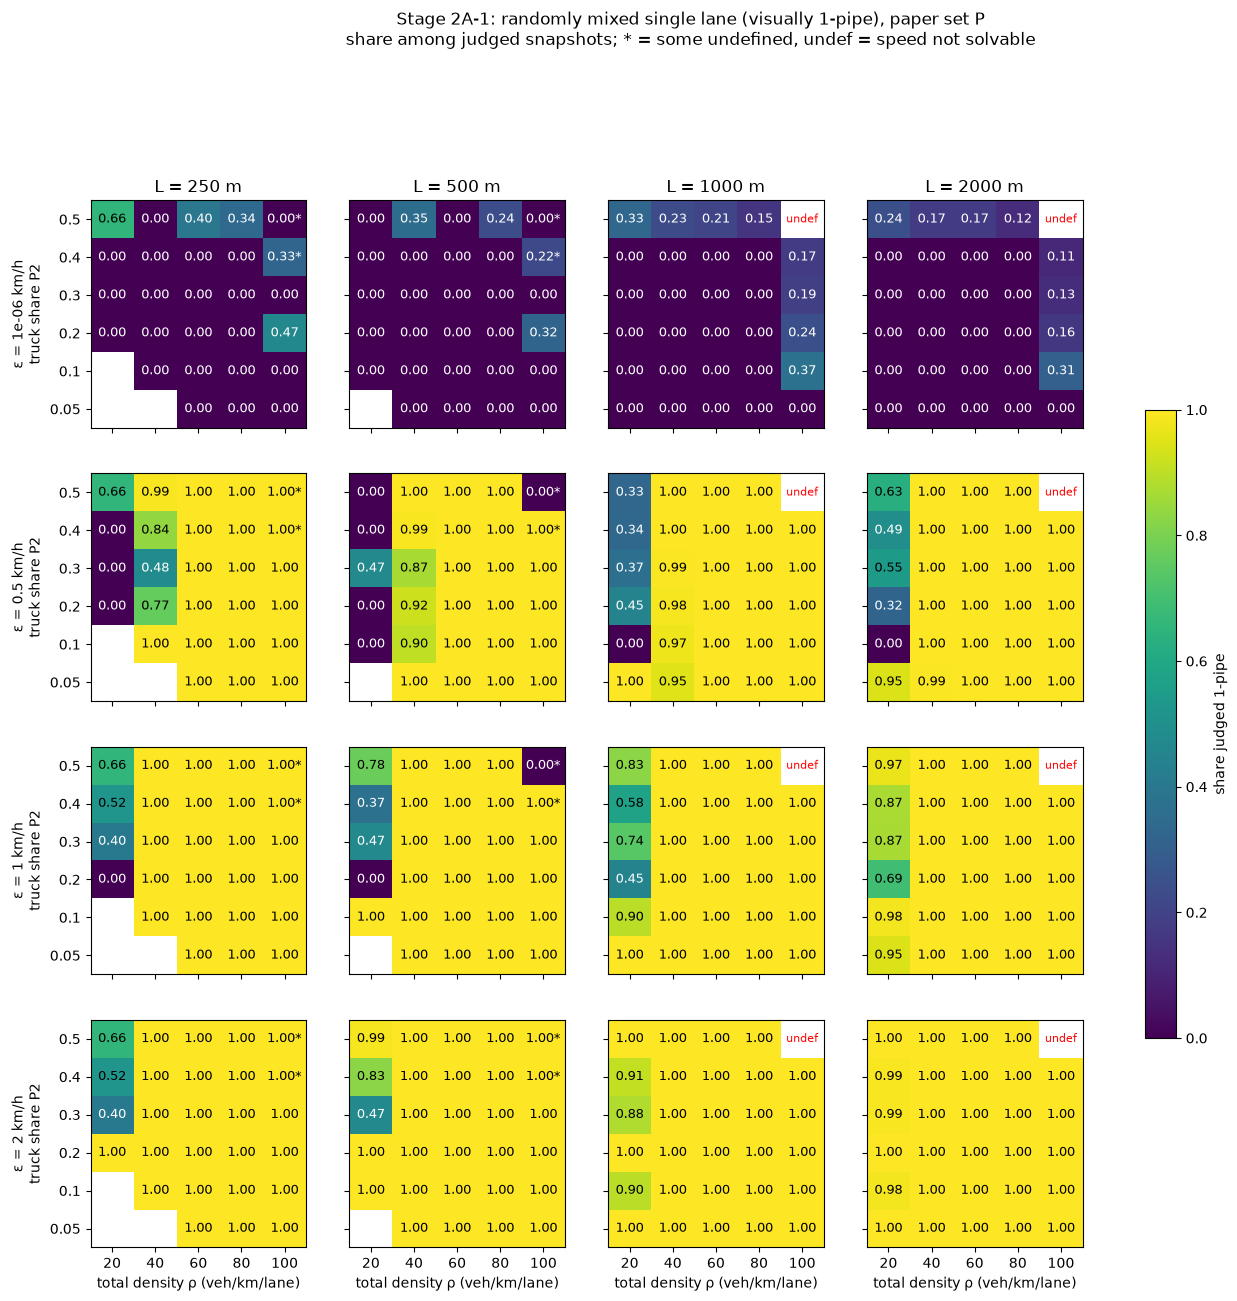

In [9]:
fig, axes = plt.subplots(len(EPS_LIST), len(L_LIST), figsize=(4 * len(L_LIST), 3.4 * len(EPS_LIST)),
                         sharex=True, sharey=True)
for a, eps in enumerate(EPS_LIST):
    for b, L in enumerate(L_LIST):
        ax = axes[a, b]
        sub = summary[summary['L'] == L].pivot(index='P2', columns='rho_tot', values=f'P1pipe_{eps:g}')
        im = ax.imshow(sub.values, origin='lower', vmin=0, vmax=1, cmap='viridis', aspect='auto')
        ax.set_xticks(range(len(sub.columns)), sub.columns)
        ax.set_yticks(range(len(sub.index)), sub.index)
        und = summary[summary['L'] == L].pivot(index='P2', columns='rho_tot', values='P_undef').values
        for i in range(sub.shape[0]):
            for j in range(sub.shape[1]):
                val = sub.values[i, j]
                if np.isfinite(val):
                    mark = '*' if und[i, j] > 0 else ''      # 一部のスナップショットが undefined
                    ax.text(j, i, f"{val:.2f}{mark}", ha='center', va='center',
                            color='white' if val < 0.5 else 'black', fontsize=9)
                elif np.isfinite(und[i, j]):                   # 条件はあるが全部 undefined
                    ax.text(j, i, "undef", ha='center', va='center', color='red', fontsize=8)
        if a == 0:
            ax.set_title(f"L = {L} m")
        if b == 0:
            ax.set_ylabel(f"ε = {eps:g} km/h\ntruck share P2")
        if a == len(EPS_LIST) - 1:
            ax.set_xlabel("total density ρ (veh/km/lane)")
fig.colorbar(im, ax=axes, shrink=0.6, label="share judged 1-pipe")
fig.suptitle("Stage 2A-1: randomly mixed single lane (visually 1-pipe), paper set P\n"
             "share among judged snapshots; * = some undefined, undef = speed not solvable", y=1.02)
plt.savefig(OUT / "stage2A1_P1pipe_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

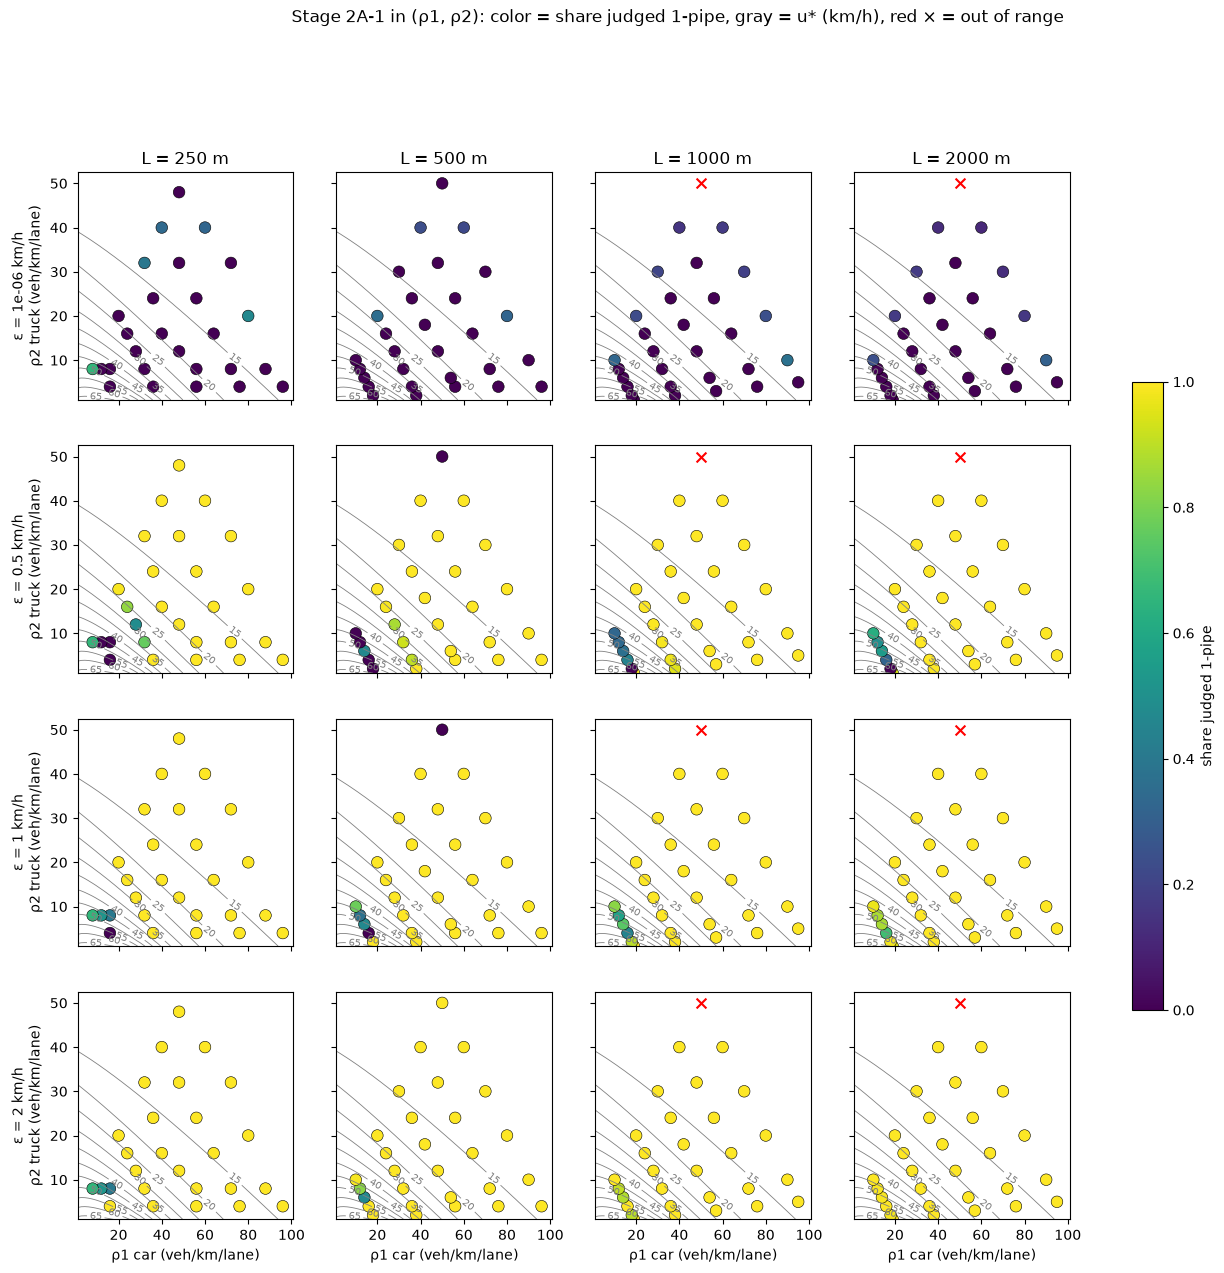

In [10]:
# ---- 背景：u*（印刷版 Eq.7）の等高線用の格子 ----
r1_max = (summary['n1'] / (summary['L'] / 1000)).max() * 1.05
r2_max = (summary['n2'] / (summary['L'] / 1000)).max() * 1.05
g1 = np.linspace(1, r1_max, 60)
g2 = np.linspace(1, r2_max, 40)
U = np.full((len(g2), len(g1)), np.nan)
for i, r2 in enumerate(g2):
    for j, r1 in enumerate(g1):
        try:
            U[i, j] = solve_1pipe_speed(r1, r2, CAR_PARAMS, TRUCK_PARAMS, A2, B1, scaling='printed')
        except Exception:
            pass                                   # 範囲外は空白のまま

# ---- 散布図 ----
summary['rho1'] = summary['n1'] / (summary['L'] / 1000)
summary['rho2'] = summary['n2'] / (summary['L'] / 1000)
valid = summary['dv_mean'].notna()                 # 範囲外（速度が解けない）条件を区別

fig, axes = plt.subplots(len(EPS_LIST), len(L_LIST), figsize=(4 * len(L_LIST), 3.4 * len(EPS_LIST)),
                         sharex=True, sharey=True)
for a, eps in enumerate(EPS_LIST):
    for b, L in enumerate(L_LIST):
        ax = axes[a, b]
        cs = ax.contour(g1, g2, U, levels=np.arange(15, 70, 5), colors='gray', linewidths=0.6)
        ax.clabel(cs, fmt='%d', fontsize=7)

        sub = summary[(summary['L'] == L) & valid]
        sc = ax.scatter(sub['rho1'], sub['rho2'], c=sub[f'P1pipe_{eps:g}'],
                        vmin=0, vmax=1, cmap='viridis', s=70, edgecolors='k', linewidths=0.4)
        bad = summary[(summary['L'] == L) & ~valid]
        ax.scatter(bad['rho1'], bad['rho2'], marker='x', color='red', s=50)

        if a == 0:
            ax.set_title(f"L = {L} m")
        if b == 0:
            ax.set_ylabel(f"ε = {eps:g} km/h\nρ2 truck (veh/km/lane)")
        if a == len(EPS_LIST) - 1:
            ax.set_xlabel("ρ1 car (veh/km/lane)")

fig.colorbar(sc, ax=axes, shrink=0.6, label="share judged 1-pipe")
fig.suptitle("Stage 2A-1 in (ρ1, ρ2): color = share judged 1-pipe, gray = u* (km/h), red × = out of range",
             y=1.0)
plt.savefig(OUT / "stage2A1_P1pipe_rho1rho2.png", dpi=150, bbox_inches='tight')
plt.show()

In [40]:
print(dv_tab[['dv_min', 'dv_max', 'dv_std']].describe().round(3))

        dv_min   dv_max   dv_std
count  114.000  114.000  113.000
mean    -0.418    0.523    0.239
std      0.714    0.865    0.419
min     -3.244    0.004    0.000
25%     -0.556    0.056    0.022
50%     -0.178    0.187    0.063
75%     -0.065    0.474    0.202
max      1.582    4.141    1.965


## 6. 図：ずれの大きさと区間の長さ
並び方のばらつき（dv_std）と最大のずれ（dv_absmax）が、区間を長くするとどう小さくなるか。
破線は 1/√L の傾き（予想）

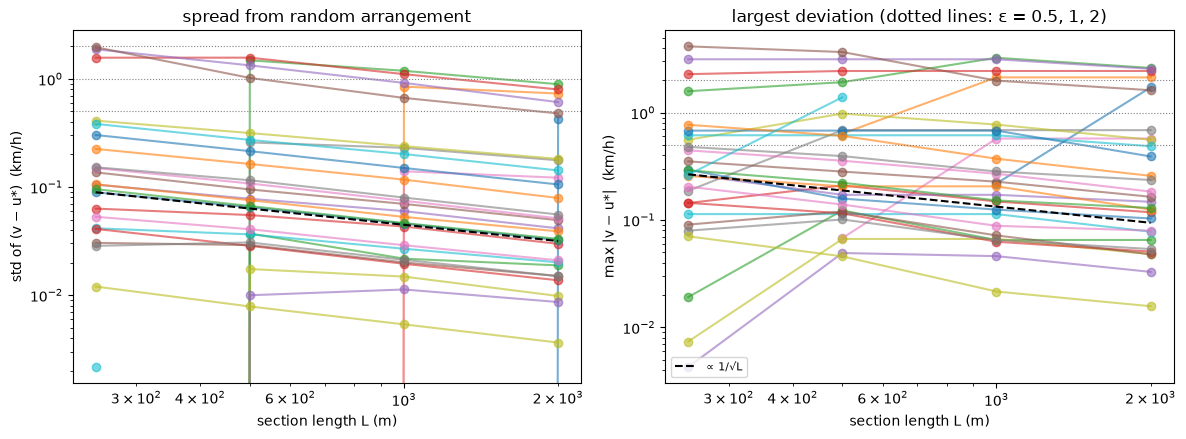

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (rho, P2), g in summary.groupby(['rho_tot', 'P2']):
    g = g.sort_values('L')
    axes[0].plot(g['L'], g['dv_std'], marker='o', alpha=0.6, label=f"ρ={rho}, P2={P2}")
    axes[1].plot(g['L'], g['dv_absmax'], marker='o', alpha=0.6)
Ls = np.array(L_LIST, dtype=float)
for ax, col in zip(axes, ['dv_std', 'dv_absmax']):
    ref = summary[summary['L'] == L_LIST[0]][col].median()
    ax.plot(Ls, ref * np.sqrt(Ls[0] / Ls), 'k--', lw=1.5, label='∝ 1/√L')
    for eps in EPS_LIST[1:]:
        ax.axhline(eps, color='gray', lw=0.8, ls=':')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel("section length L (m)")
axes[0].set_ylabel("std of (v − u*)  (km/h)")
axes[1].set_ylabel("max |v − u*|  (km/h)")
axes[0].set_title("spread from random arrangement")
axes[1].set_title("largest deviation (dotted lines: ε = 0.5, 1, 2)")
axes[1].legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "stage2A1_deviation_vs_L.png", dpi=150, bbox_inches='tight')
plt.show()

## 7. 1-pipe と判定されなかったときの内訳（ε = 2 km/h、Chen の値）
1-pipe でなければ、u* より速い（2-pipe と誤判定）か、遅い（non-NE と誤判定）のどちらか

In [42]:
eps = 2.0
P_undef = df['dv'].isna().groupby([df[k] for k in keys]).mean().rename('P_undef').reset_index()
summary = summary.drop(columns='P_undef', errors='ignore').merge(P_undef, on=keys)
cols = [f'P1pipe_{eps:g}', f'P2pipe_{eps:g}', f'PnonNE_{eps:g}']
summary[keys + ['n1', 'n2', 'P_undef', 'dv_mean', 'dv_absmax'] + cols].query(f"`P1pipe_{eps:g}` < 1 or P_undef > 0").round(3)

,L,rho_tot,P2,n1,n2,P_undef,dv_mean,dv_absmax,P1pipe_2,P2pipe_2,PnonNE_2
1,250,20,0.3,4,2,0.000,0.990,2.282,0.404,0.596,0.000
2,250,20,0.4,3,2,0.000,1.175,3.139,0.522,0.478,0.000
3,250,20,0.5,2,2,0.000,1.416,4.141,0.658,0.342,0.000
25,250,100,0.4,15,10,0.003,0.005,0.070,0.997,0.000,0.000
26,250,100,0.5,12,12,0.844,0.254,0.263,0.156,0.000,0.000
29,500,20,0.3,7,3,0.000,0.801,2.442,0.470,0.448,0.082
30,500,20,0.4,6,4,0.000,0.559,3.139,0.826,0.130,0.044
31,500,20,0.5,5,5,0.000,0.394,3.669,0.988,0.012,0.000
54,500,100,0.4,30,20,0.001,0.002,0.046,0.999,0.000,0.000
55,500,100,0.5,25,25,0.999,1.389,1.389,0.001,0.000,0.000


---
# 8. Stage 2A-1 OV版：名目速度関数を OV形にして同じことをする

ここまで（§0〜7）と変えるのは**名目速度関数の形だけ**。並べ方・判定の流れは同じ。

**使う OV形：スケール形**　V_ij(h) = V_ii(a_ij · h)（`make_ov_nominal(form='scale')`）
- a2, b1 はセットP（論文の値 0.4528, 2.5996）のまま
- スケーリング R_ij = a_ij · R_ii が厳密に成り立つので、平均の m̄ では印刷版 Eq.7 = 円環の正解になる
  → §0〜7 と同じく、**ずれの原因は並び方だけ**（形が違うことの影響だけを見られる）
- ギャップ形（x = h − ℓ_j）は使わない：B(v) ≡ 0 で速度が m によらない（Q1 ②b-2）ので、並び方の実験にならない。
  さらにアルゴリズム側の a2, b1 を推定しないといけないので Stage 3-3 で扱う

**アルゴリズム側には正解の OV関数をそのまま渡す（推定しない）**
- src の `solve_1pipe_speed`, `compute_min_road_share` は論文形専用なので、印刷版 Eq.7 と p_i* = ρ_i / R_i(u*) はここで書く
  （円環の式 Σn·h = L ではなく、**Eq.7 の形のまま**書く）
- s, 判定, 協力の存在判定は src（`compute_cooperation_surplus`, `classify_traffic_regime`, `check_cooperation_existence`）をそのまま使う

**§0〜7 との大きな違い：s > 0 になる**
- 論文形（セットP）では s < 0 だったが、同じ a2, b1 でも OV形の自クラス関数だと s > 0（Q1 ②b-1 と同じ）
- 見た目は混合なので、正解のラベルは **L2（1-pipe 非パレートNE）**。協力はない
- 2-pipe と誤判定されると、s > 0 なので**協力ありと誤判定**される（偽の協力）。これも数える

**OV の値は仮置き**（最高速度 120/90 km/h、車長 4.5/12 m、l0 = 12.5 m、c = 2）。
同じ密度でも論文形より遅く、ρ ≲ 26 veh/km ではトラックの最高速度 90 km/h に張り付いて速度が数値的に決まらない
（tanh が漸近するだけなので、上限の取り方で s が変わる）。そこで密度は ρ = 30, 35, 40, 50 にする（u* は約 70〜11 km/h）

In [44]:
from src.ring_equilibrium import make_ov_nominal, R_eq, surplus_at
from src.whole_pipeline import check_cooperation_existence
from scipy.optimize import brentq

# 正解側も、アルゴリズム側も、この OV関数を使う
OV_NOMINAL = make_ov_nominal(form='scale', scale={(1, 2): A2, (2, 1): B1})   # vmax・車長・形は既定値（仮置き）
RHO_TOT_OV = [30, 35, 40, 50]          # 全体の密度 (veh/km/lane)。P2_LIST, L_LIST, EPS_LIST, N_SHUFFLE は §0 と同じ

V_HI_OV = min(v_range(OV_NOMINAL, i, j)[1] for i, j in [(1, 1), (1, 2), (2, 2), (2, 1)])
print(f"OV形の速度の上限（トラックの最高速度）: {V_HI_OV:.4f} km/h")
print("車長:", OV_NOMINAL['length'], " 最高速度:", OV_NOMINAL['vmax'], " 形:", OV_NOMINAL['shape'])

OV形の速度の上限（トラックの最高速度）: 90.0000 km/h
車長: {1: 4.5, 2: 12.0}  最高速度: {1: 120.0, 2: 90.0}  形: {'l0': 12.5, 'c': 2.0}



### 8-0. 仮置きの OV形の名目速度関数（追従ペアごと）
4種類の追従ペア (自車, 先行車) の速度–密度関数 u_ij(ρ) = V_ij(1000/ρ) を描く。
- 左：§8 で使うスケール形 V_ij(h) = V_ii(a_ij·h)（a2, b1 = セットP）
- 中：参考のギャップ形 V_i(h − ℓ_j)（§8 では使わない）
- 右：比較用の論文形（セットP）
- 灰色の帯は §8 の密度の範囲（ρ = 30〜50 veh/km）。ここでの ρ は追従ペアの車間から決まるミクロな密度 1000/h


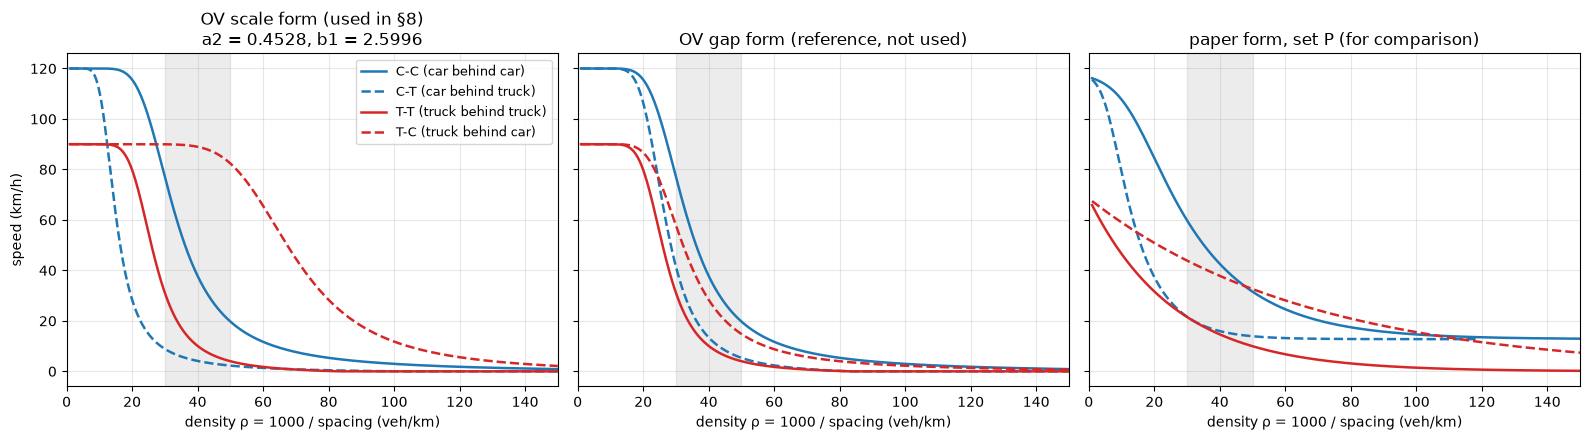

In [45]:

from src.ring_equilibrium import u_nominal

OV_GAP = make_ov_nominal(form='gap')        # 参考：ギャップ形（vmax・車長・形は同じ既定値）
PAIR_STYLE = {(1, 1): ('C-C (car behind car)', 'tab:blue', '-'),
              (1, 2): ('C-T (car behind truck)', 'tab:blue', '--'),
              (2, 2): ('T-T (truck behind truck)', 'tab:red', '-'),
              (2, 1): ('T-C (truck behind car)', 'tab:red', '--')}
rho_grid = np.linspace(1, 150, 600)          # veh/km

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
panels = [(OV_NOMINAL, f"OV scale form (used in §8)\na2 = {A2}, b1 = {B1}"),
          (OV_GAP, "OV gap form (reference, not used)"),
          (NOMINAL, "paper form, set P (for comparison)")]
for ax, (nom, title) in zip(axes, panels):
    for pair, (label, color, ls) in PAIR_STYLE.items():
        u = u_nominal(nom, *pair, rho_grid)
        if nom['kind'] == 'paper':           # 論文形は使える速度の範囲の外を描かない
            lo, hi = v_range(nom, *pair)
            u = np.where((u > lo) & (u < hi), u, np.nan)
        ax.plot(rho_grid, u, color=color, ls=ls, lw=1.8, label=label)
    ax.axvspan(min(RHO_TOT_OV), max(RHO_TOT_OV), color='gray', alpha=0.15)
    ax.set_title(title)
    ax.set_xlabel("density ρ = 1000 / spacing (veh/km)")
    ax.set_xlim(0, 150)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("speed (km/h)")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "stage2A1_OV_nominal_curves.png", dpi=150, bbox_inches='tight')
plt.show()


## 8-1. 部品（OV版）
- `eq7_speed_general`：印刷版 Eq.7 を、自クラスの R_i(u) を渡せる形で解く（論文形でも OV形でも使える）
  　(1/ρ)[(ρ1/R1(u))(ρ1 + ρ2/a2) + (ρ2/R2(u))(ρ1/b1 + ρ2)] = 1
- `ring_speed_general`：§1 の `ring_speed` の、名目速度関数と上限を引数で渡せる版
- `build_observations`：§2 のループを関数にしたもの。正解の s（観測速度 v での s）も一緒に記録する

In [14]:
def eq7_speed_general(nominal, a2, b1, rho1, rho2, v_lo, v_hi):
    """
    印刷版 Eq.7 の u* を解く。R_i(u) は nominal の自クラスの関数 R_ii(u) を使う。
    v_lo, v_hi: 探す速度の範囲（名目速度関数が使える範囲）。
    解けない・上限に張り付く場合は NaN
    """
    rho = rho1 + rho2
    def f(u):
        R1 = R_eq(nominal, CAR, CAR, u)
        R2 = R_eq(nominal, TRUCK, TRUCK, u)
        return (rho1 / R1 * (rho1 + rho2 / a2) + rho2 / R2 * (rho1 / b1 + rho2)) / rho - 1.0
    lo, hi = v_lo, v_hi
    if f(lo) > 0 or f(hi) < 0:       # 詰め込みすぎ／上限まで来ても道路が余る
        return np.nan
    u = brentq(f, lo, hi, xtol=1e-12)
    return np.nan if u >= v_hi - 1e-9 else u


def ring_speed_general(nominal, v_hi, n1, n2, m, L):
    """§1 の ring_speed と同じ。名目速度関数と速度の上限を引数で渡す"""
    v = lane_speed(nominal, pair_counts(n1, n2, int(m)), L)
    if not np.isfinite(v) or v >= v_hi - 1e-9:
        return np.nan
    return v


def build_observations(nominal, v_hi, rho_list, p2_list, l_list, n_shuffle, seed):
    """
    §2 のループと同じ。条件ごとにランダムに並べて m を数え、円環の定常速度 v（観測速度）を解く。
    s_true = 観測速度 v での協力余剰（正解のラベル L1/L2 を決めるのに使う）
    """
    rng = np.random.default_rng(seed)
    rows, conds = [], []
    for L in l_list:
        for rho in rho_list:
            for P2 in p2_list:
                n1 = int(round(rho * (1 - P2) * L / 1000))
                n2 = int(round(rho * P2 * L / 1000))
                if n1 == 0 or n2 == 0:
                    continue
                rho1, rho2 = n1 / (L / 1000), n2 / (L / 1000)

                m_samples = sample_m(n1, n2, n_shuffle, rng)
                v_of_m = {m: ring_speed_general(nominal, v_hi, n1, n2, m, L) for m in np.unique(m_samples)}
                s_true_of_m = {m: float(surplus_at(nominal, rho1, rho2, v)['s']) for m, v in v_of_m.items()}
                v_avg = lane_speed(nominal, pair_counts(n1, n2, None), L)

                conds.append({'L': L, 'rho_tot': rho, 'P2': P2, 'n1': n1, 'n2': n2,
                              'rho1': rho1, 'rho2': rho2, 'm_bar': n1 * n2 / (n1 + n2), 'v_avg': v_avg,
                              'n_m_kinds': len(v_of_m)})
                for k, m in enumerate(m_samples):
                    rows.append({'L': L, 'rho_tot': rho, 'P2': P2, 'shuffle': k,
                                 'rho1': rho1, 'rho2': rho2, 'm': m,
                                 'u1_obs': v_of_m[m], 'u2_obs': v_of_m[m], 's_true': s_true_of_m[m]})
    return pd.DataFrame(rows), pd.DataFrame(conds)


# 確認：論文形（NOMINAL）で eq7_speed_general を解くと、src の solve_1pipe_speed と一致するはず
r1, r2 = 36.0, 4.0
u_src = solve_1pipe_speed(r1, r2, CAR_PARAMS, TRUCK_PARAMS, A2, B1, scaling='printed')
u_gen = eq7_speed_general(NOMINAL, A2, B1, r1, r2, V_LO, V_HI)
print(f"論文形で確認: src {u_src:.10f}  /  ここで書いた Eq.7 {u_gen:.10f}  差 {u_gen - u_src:.1e} km/h")

論文形で確認: src 36.1998505551  /  ここで書いた Eq.7 36.1998505551  差 0.0e+00 km/h


## 8-2. 観測データを作って、アルゴリズムを流す

In [15]:
df_obs_ov, df_cond_ov = build_observations(OV_NOMINAL, V_HI_OV, RHO_TOT_OV, P2_LIST, L_LIST, N_SHUFFLE, SEED)
print(f"条件 {len(df_cond_ov)} 通り、スナップショット {len(df_obs_ov):,} 枚")
print(f"速度が範囲外（NaN）のスナップショット: {df_obs_ov['u1_obs'].isna().sum():,} 枚")

# Step 3a: u*（印刷版 Eq.7、正解の OV関数を使う）
df_cond_ov['u_1pipe'] = [eq7_speed_general(OV_NOMINAL, A2, B1, r['rho1'], r['rho2'], 1e-6, V_HI_OV)
                         for _, r in df_cond_ov.iterrows()]
df_cond_ov['v_avg_minus_ustar'] = df_cond_ov['v_avg'] - df_cond_ov['u_1pipe']   # 0 のはず

df_ov = df_obs_ov.merge(df_cond_ov[['L', 'rho_tot', 'P2', 'u_1pipe']], on=['L', 'rho_tot', 'P2'])
# Step 3b: p_i* = ρ_i / R_i(u*)（OV の自クラス関数）
df_ov['p1_star'] = df_ov['rho1'] / R_eq(OV_NOMINAL, CAR, CAR, df_ov['u_1pipe'].values)
df_ov['p2_star'] = df_ov['rho2'] / R_eq(OV_NOMINAL, TRUCK, TRUCK, df_ov['u_1pipe'].values)
df_ov = compute_cooperation_surplus(df_ov)                    # Step 3c（src）
df_ov['dv'] = df_ov['u1_obs'] - df_ov['u_1pipe']

# 正解のラベル：見た目は混合 → s_true < 0 なら L1（1-pipe パレートNE）、s_true > 0 なら L2（1-pipe 非パレートNE）
df_ov['label'] = np.where(df_ov['s_true'] > 0, 'L2', 'L1')

# Step 4, 5: ε ごとに判定し、協力の存在も判定する（src）
regimes_ov, coop_ov = {}, {}
for eps in EPS_LIST:
    out = check_cooperation_existence(classify_traffic_regime(df_ov, eps_kmh=eps))
    regimes_ov[eps] = out['regime']
    coop_ov[eps] = out['coop_exists']

print(f"\nv_avg − u* の最大値（平均の m̄ なら 0 のはず）: {df_cond_ov['v_avg_minus_ustar'].abs().max():.1e} km/h")
print(f"アルゴリズムの s（u* での値）: 最小 {df_ov['s'].min():.4f}, 最大 {df_ov['s'].max():.4f}")
print(f"正解の s（観測速度での値）  : 最小 {df_ov['s_true'].min():.4f}, 最大 {df_ov['s_true'].max():.4f}")
print("正解のラベル:", df_ov['label'].value_counts().to_dict())

条件 93 通り、スナップショット 93,000 枚
速度が範囲外（NaN）のスナップショット: 0 枚
協力余剰sを計算: 93,000スナップショット中、93,000件で計算完了（うちs>0: 93,000件）
交通状態を判定(eps: 車 0.00, トラック 0.00 km/h): 判定対象 93,000件 (対象外 undefined: 0件)
      2-pipe: 27,325件 (29.38%)
      1-pipe: 6,440件 (6.92%)
      non-NE: 59,235件 (63.69%)
  Pcoop = 29.38% (論文: 13.83%)
  平均s: 2-pipe = 0.0490, 1-pipe = 0.0491 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 93,000件
  s>0             : 93,000件 (100.00%)
  2-pipe          : 27,325件 (29.38%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 27,325件 (29.38%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 0件 (0.00% of 2-pipe)  ← 命題1と不整合
交通状態を判定(eps: 車 0.50, トラック 0.50 km/h): 判定対象 93,000件 (対象外 undefined: 0件)
      2-pipe: 12,172件 (13.09%)
      1-pipe: 59,735件 (64.23%)
      non-NE: 21,093件 (22.68%)
  Pcoop = 13.09% (論文: 13.83%)
  平均s: 2-pipe = 0.0536, 1-pipe = 0.0371 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 93,000件
  s>0             : 93,000件 (100.00%)
  2-pipe          : 12,172件 (13.09%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 12,172件 (13.09%)  ← 協力性あり(Step6で使う)
  

交通状態を判定(eps: 車 2.00, トラック 2.00 km/h): 判定対象 93,000件 (対象外 undefined: 0件)
      2-pipe: 2,230件 (2.40%)
      1-pipe: 86,163件 (92.65%)
      non-NE: 4,607件 (4.95%)
  Pcoop = 2.40% (論文: 13.83%)
  平均s: 2-pipe = 0.0592, 1-pipe = 0.0421 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 93,000件
  s>0             : 93,000件 (100.00%)
  2-pipe          : 2,230件 (2.40%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 2,230件 (2.40%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 0件 (0.00% of 2-pipe)  ← 命題1と不整合

v_avg − u* の最大値（平均の m̄ なら 0 のはず）: 3.6e-14 km/h
アルゴリズムの s（u* での値）: 最小 0.0109, 最大 0.0685
正解の s（観測速度での値）  : 最小 0.0054, 最大 0.1177
正解のラベル: {'L2': 93000}


## 8-3. 集計（OV版）
§4 の列に加えて
- `Pcoop_eps`：**協力ありと判定された割合**（2-pipe かつ s > 0）。見た目は混合なので、これは全部誤り（偽の協力）
- `share_L2`：正解のラベルが L2（s_true > 0）のスナップショットの割合

In [16]:
summary_ov = df_ov.groupby(keys).agg(dv_mean=('dv', 'mean'), dv_std=('dv', 'std'),
                                     dv_absmax=('dv', lambda x: x.abs().max()),
                                     s_algo=('s', 'mean'), share_L2=('label', lambda x: (x == 'L2').mean())
                                     ).reset_index()
summary_ov = df_cond_ov[keys + ['n1', 'n2', 'm_bar', 'n_m_kinds', 'u_1pipe']].merge(summary_ov, on=keys)

undef_ov = (regimes_ov[EPS_LIST[0]] == 'undefined').groupby([df_ov[k] for k in keys]).mean().rename('P_undef')
summary_ov = summary_ov.merge(undef_ov.reset_index(), on=keys)

# 割合の分母は判定対象（undefined 以外）。§4 と同じ
for eps in EPS_LIST:
    r = regimes_ov[eps]
    judged = r != 'undefined'
    tab = pd.DataFrame({'1-pipe': r == '1-pipe', '2-pipe': r == '2-pipe', 'non-NE': r == 'non-NE',
                        'coop': coop_ov[eps]})[judged]
    tab[keys] = df_ov.loc[judged, keys]
    g = tab.groupby(keys)[['1-pipe', '2-pipe', 'non-NE', 'coop']].mean().reset_index()
    g = g.rename(columns={'1-pipe': f'P1pipe_{eps:g}', '2-pipe': f'P2pipe_{eps:g}',
                          'non-NE': f'PnonNE_{eps:g}', 'coop': f'Pcoop_{eps:g}'})
    summary_ov = summary_ov.merge(g, on=keys, how='left')

summary_ov.to_csv(OUT / "stage2A1_OV_summary.csv", index=False, encoding='utf-8-sig')
summary_ov[keys + ['n1', 'n2', 'u_1pipe', 'P_undef', 's_algo', 'dv_mean', 'dv_std', 'dv_absmax']
           + [f'P1pipe_{e:g}' for e in EPS_LIST] + [f'Pcoop_{e:g}' for e in EPS_LIST]].round(3)

,L,rho_tot,P2,n1,n2,u_1pipe,P_undef,s_algo,dv_mean,dv_std,dv_absmax,P1pipe_1e-06,P1pipe_0.5,P1pipe_1,P1pipe_2,Pcoop_1e-06,Pcoop_0.5,Pcoop_1,Pcoop_2
0,250,30,0.1,7,1,55.155,0.0,0.035,-0.701,0.000,0.701,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000
1,250,30,0.2,6,2,46.038,0.0,0.056,-0.921,2.158,2.445,0.000,0.000,0.000,0.000,0.291,0.291,0.291,0.291
2,250,30,0.3,5,2,62.043,0.0,0.060,-1.591,2.760,3.410,0.000,0.000,0.000,0.000,0.303,0.303,0.303,0.303
3,250,30,0.4,4,3,53.845,0.0,0.068,-1.696,3.286,6.708,0.000,0.000,0.000,0.623,0.168,0.168,0.168,0.168
4,250,30,0.5,4,4,34.320,0.0,0.065,-0.782,2.322,5.951,0.508,0.508,0.508,0.508,0.123,0.123,0.123,0.123
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,2000,50,0.1,90,10,15.953,0.0,0.023,-0.008,0.108,0.375,0.412,1.000,1.000,1.000,0.227,0.000,0.000,0.000
89,2000,50,0.2,80,20,13.211,0.0,0.037,-0.013,0.141,0.561,0.249,0.999,1.000,1.000,0.326,0.001,0.000,0.000
90,2000,50,0.3,70,30,11.142,0.0,0.042,-0.012,0.139,0.448,0.208,1.000,1.000,1.000,0.357,0.000,0.000,0.000
91,2000,50,0.4,60,40,9.525,0.0,0.042,-0.010,0.123,0.391,0.175,1.000,1.000,1.000,0.380,0.000,0.000,0.000


## 8-4. 論文形と OV形の比較（全条件をまとめた割合）
条件の組み合わせ（密度）が違うので、数字は「その条件の範囲での」割合

In [17]:
def overall_shares(df_algo, regimes_dict, coop_dict=None):
    """ε ごとに、判定対象（undefined 以外）の中での 1-pipe / 2-pipe / non-NE / 協力あり の割合"""
    out = []
    for eps in EPS_LIST:
        r = regimes_dict[eps]
        judged = r != 'undefined'
        row = {'eps': eps, 'n_judged': int(judged.sum()),
               '1-pipe': (r[judged] == '1-pipe').mean(),
               '2-pipe': (r[judged] == '2-pipe').mean(),
               'non-NE': (r[judged] == 'non-NE').mean()}
        if coop_dict is not None:
            row['協力あり（誤り）'] = coop_dict[eps][judged].mean()
        out.append(row)
    return pd.DataFrame(out)

cmp = pd.concat({'論文形（セットP, s<0）': overall_shares(df, regimes),
                 'OV スケール形（s>0）': overall_shares(df_ov, regimes_ov, coop_ov)}, names=['名目速度関数'])
cmp.round(3)

eps  n_judged  1-pipe  2-pipe  non-NE  協力あり（誤り）
名目速度関数                                                           
論文形（セットP, s<0） 0  0.0    112153   0.059   0.621   0.319       NaN
               1  0.5    112153   0.859   0.100   0.041       NaN
               2  1.0    112153   0.938   0.052   0.010       NaN
               3  2.0    112153   0.978   0.020   0.002       NaN
OV スケール形（s>0）  0  0.0     93000   0.069   0.294   0.637     0.294
               1  0.5     93000   0.642   0.131   0.227     0.131
               2  1.0     93000   0.804   0.073   0.123     0.073
               3  2.0     93000   0.926   0.024   0.050     0.024

## 8-5. 図（OV版）
上段：1-pipe と判定された割合（§5 と同じ図）／下段：協力ありと誤判定された割合

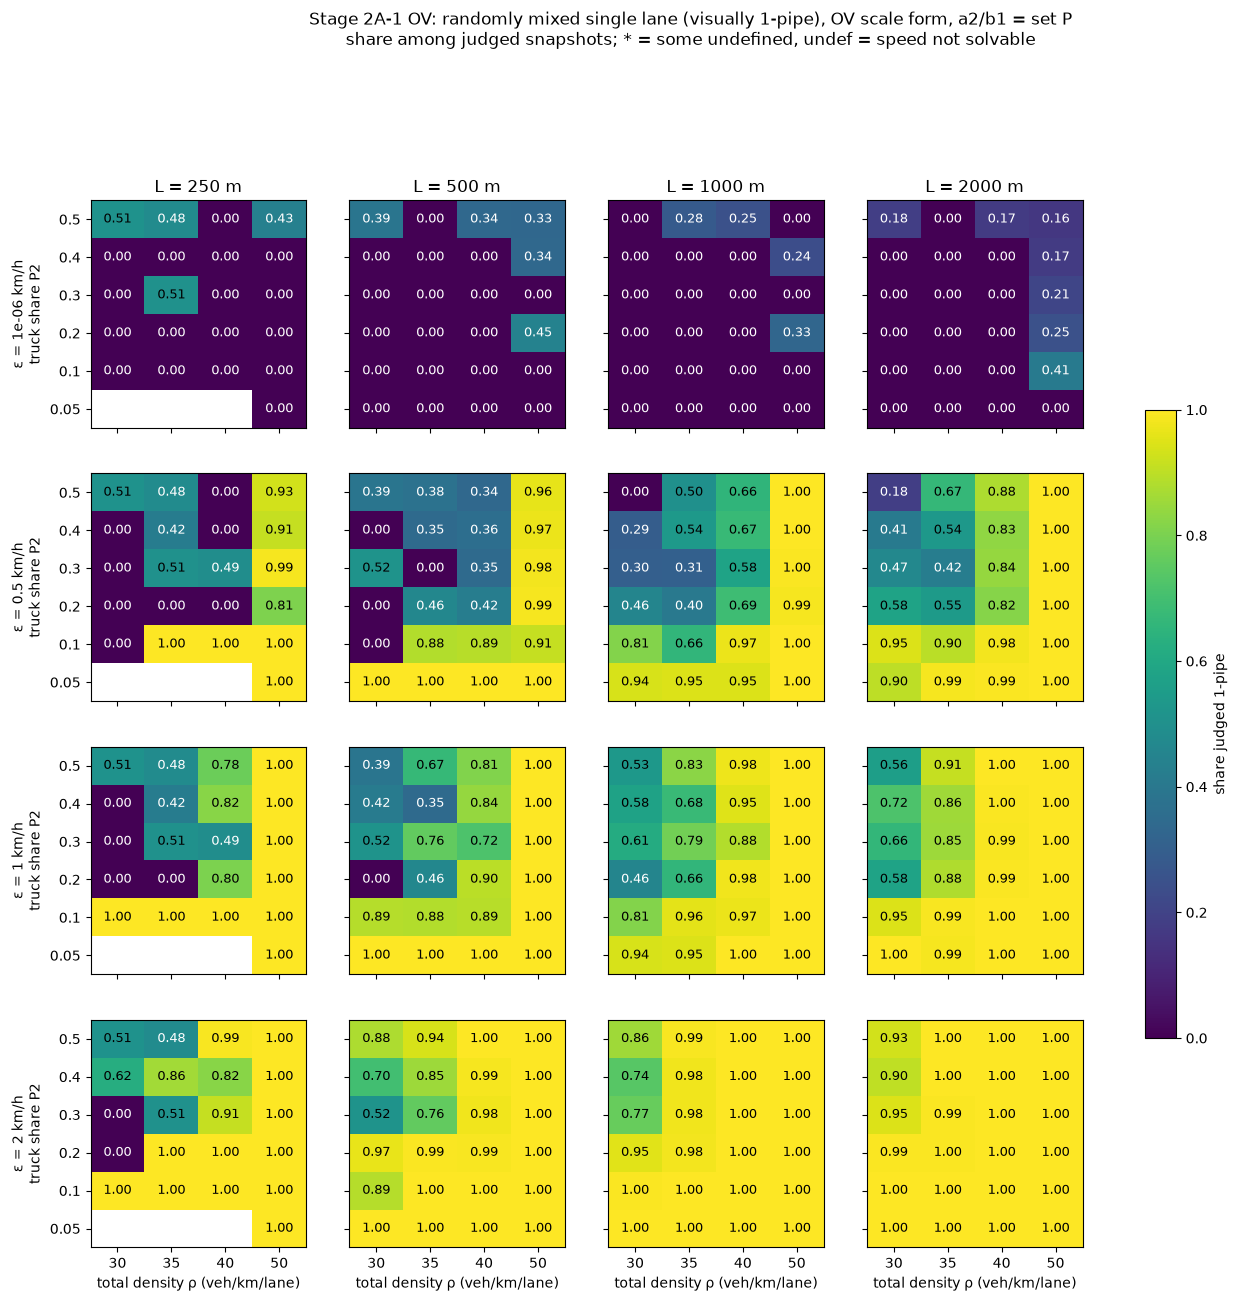

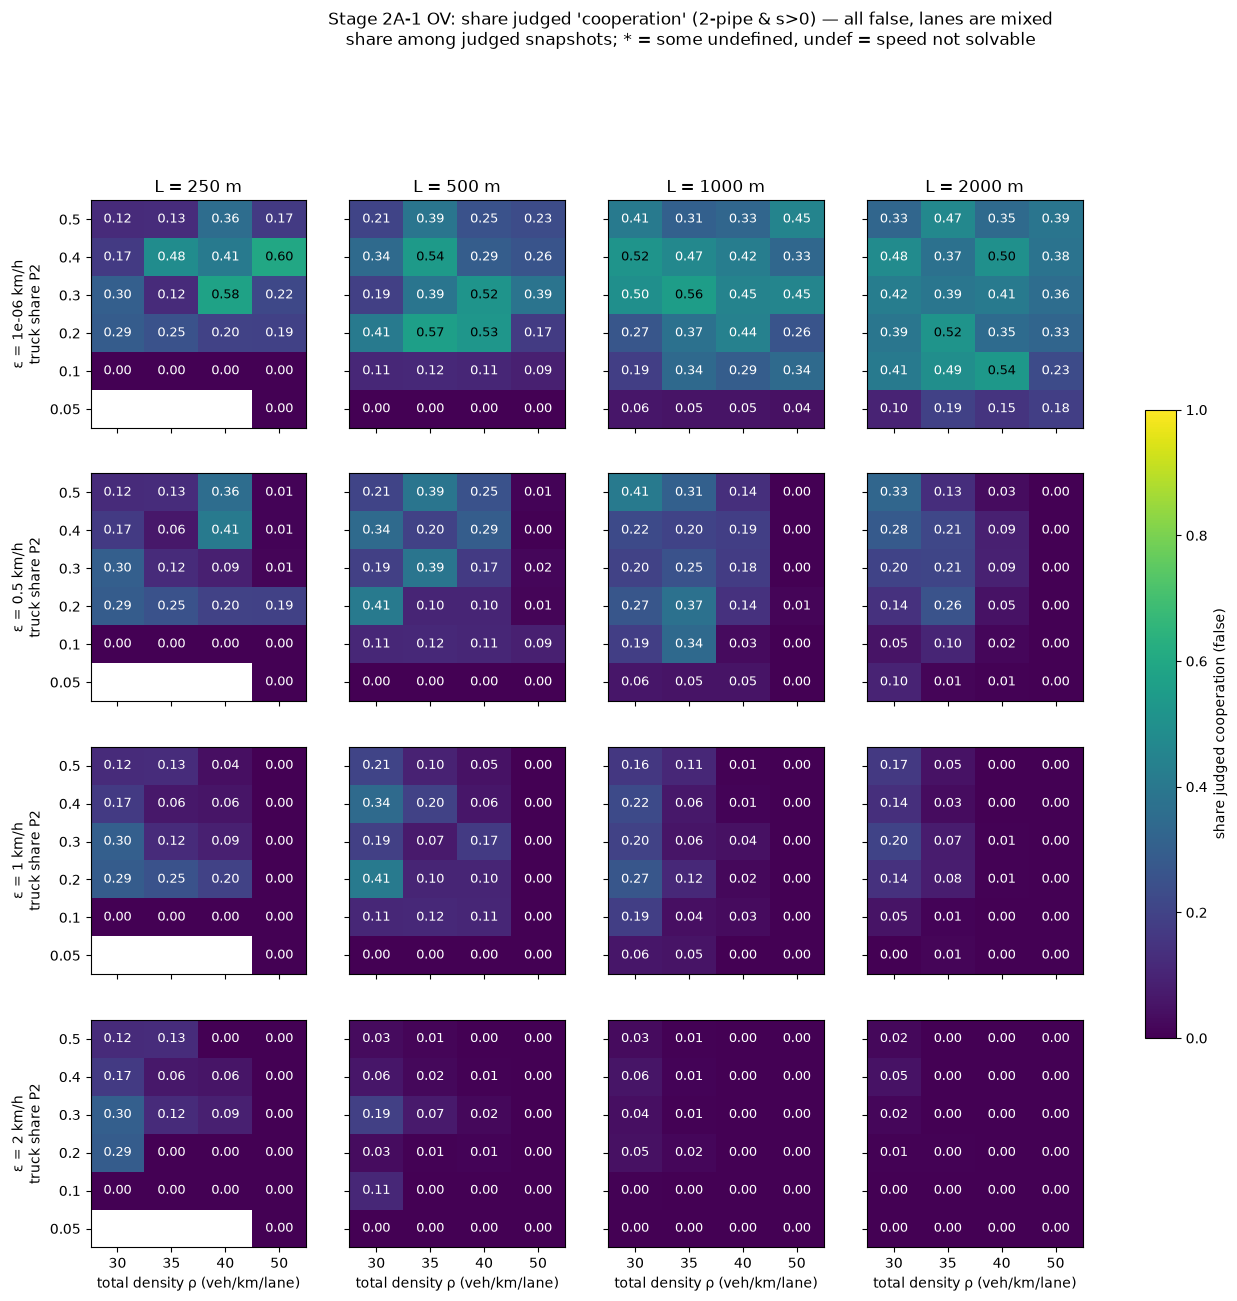

In [18]:
def plot_share_heatmaps(summary_tab, col_prefix, title, fname, cbar_label):
    """§5 と同じ形のヒートマップ（縦 ε × 横 L、各パネルは 密度 × トラックの割合）"""
    fig, axes = plt.subplots(len(EPS_LIST), len(L_LIST), figsize=(4 * len(L_LIST), 3.4 * len(EPS_LIST)),
                             sharex=True, sharey=True)
    for a, eps in enumerate(EPS_LIST):
        for b, L in enumerate(L_LIST):
            ax = axes[a, b]
            sub = summary_tab[summary_tab['L'] == L].pivot(index='P2', columns='rho_tot',
                                                           values=f'{col_prefix}_{eps:g}')
            im = ax.imshow(sub.values, origin='lower', vmin=0, vmax=1, cmap='viridis', aspect='auto')
            ax.set_xticks(range(len(sub.columns)), sub.columns)
            ax.set_yticks(range(len(sub.index)), sub.index)
            und = summary_tab[summary_tab['L'] == L].pivot(index='P2', columns='rho_tot', values='P_undef').values
            for i in range(sub.shape[0]):
                for j in range(sub.shape[1]):
                    val = sub.values[i, j]
                    if np.isfinite(val):
                        mark = '*' if und[i, j] > 0 else ''      # 一部のスナップショットが undefined
                        ax.text(j, i, f"{val:.2f}{mark}", ha='center', va='center',
                                color='white' if val < 0.5 else 'black', fontsize=9)
                    elif np.isfinite(und[i, j]):                   # 条件はあるが全部 undefined
                        ax.text(j, i, "undef", ha='center', va='center', color='red', fontsize=8)
            if a == 0:
                ax.set_title(f"L = {L} m")
            if b == 0:
                ax.set_ylabel(f"ε = {eps:g} km/h\ntruck share P2")
            if a == len(EPS_LIST) - 1:
                ax.set_xlabel("total density ρ (veh/km/lane)")
    fig.colorbar(im, ax=axes, shrink=0.6, label=cbar_label)
    fig.suptitle(title + "\nshare among judged snapshots; * = some undefined, undef = speed not solvable", y=1.02)
    plt.savefig(OUT / fname, dpi=150, bbox_inches='tight')
    plt.show()

plot_share_heatmaps(summary_ov, 'P1pipe',
                    "Stage 2A-1 OV: randomly mixed single lane (visually 1-pipe), OV scale form, a2/b1 = set P",
                    "stage2A1_OV_P1pipe_heatmap.png", "share judged 1-pipe")
plot_share_heatmaps(summary_ov, 'Pcoop',
                    "Stage 2A-1 OV: share judged 'cooperation' (2-pipe & s>0) — all false, lanes are mixed",
                    "stage2A1_OV_Pcoop_heatmap.png", "share judged cooperation (false)")

## 8-6. 図：ずれの大きさと速度（論文形と OV形）
同じ並び方のばらつきでも、名目速度関数の傾きが違えば速度のずれが変わるはず。横軸を u* にして並べる

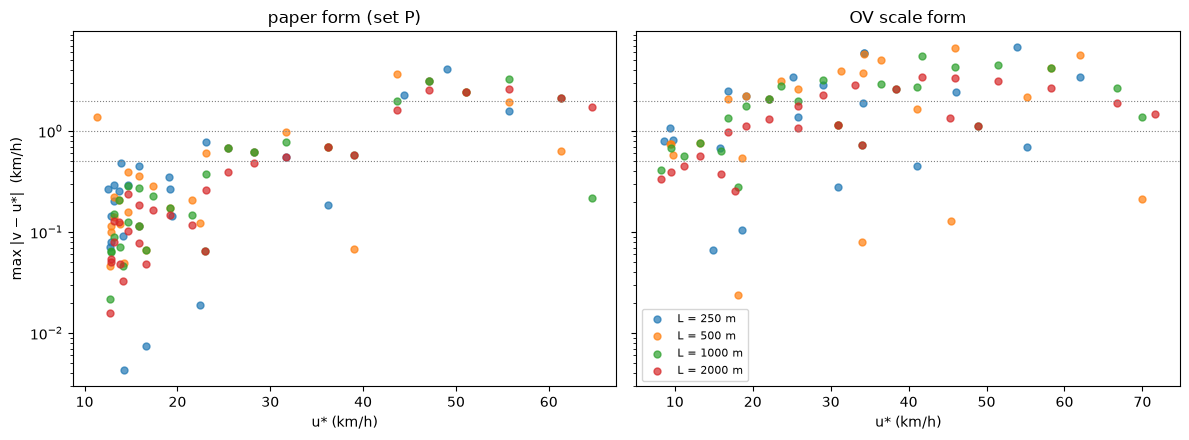

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, summ) in zip(axes, [('paper form (set P)', summary), ('OV scale form', summary_ov)]):
    for L, g in summ.groupby('L'):
        ax.scatter(g['u_1pipe'], g['dv_absmax'], s=25, alpha=0.7, label=f"L = {L} m")
    for eps in EPS_LIST[1:]:
        ax.axhline(eps, color='gray', lw=0.8, ls=':')
    ax.set_yscale('log')
    ax.set_xlabel("u* (km/h)")
    ax.set_title(name)
axes[0].set_ylabel("max |v − u*|  (km/h)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "stage2A1_OV_deviation_vs_speed.png", dpi=150, bbox_inches='tight')
plt.show()

## 8-7. 1-pipe と判定されなかったときの内訳（OV版、ε = 2 km/h）

In [20]:
eps = 2.0
cols = [f'P1pipe_{eps:g}', f'P2pipe_{eps:g}', f'PnonNE_{eps:g}', f'Pcoop_{eps:g}']
summary_ov[keys + ['n1', 'n2', 'u_1pipe', 'P_undef', 'dv_mean', 'dv_absmax'] + cols].query(f"`P1pipe_{eps:g}` < 1 or P_undef > 0").round(3)

,L,rho_tot,P2,n1,n2,u_1pipe,P_undef,dv_mean,dv_absmax,P1pipe_2,P2pipe_2,PnonNE_2,Pcoop_2
1,250,30,0.2,6,2,46.038,0.0,-0.921,2.445,0.000,0.291,0.709,0.291
2,250,30,0.3,5,2,62.043,0.0,-1.591,3.410,0.000,0.303,0.697,0.303
3,250,30,0.4,4,3,53.845,0.0,-1.696,6.708,0.623,0.168,0.209,0.168
4,250,30,0.5,4,4,34.320,0.0,-0.782,5.951,0.508,0.123,0.369,0.123
7,250,35,0.3,6,3,29.057,0.0,-0.571,2.870,0.505,0.122,0.373,0.122
8,250,35,0.4,5,4,25.198,0.0,-0.569,3.441,0.862,0.064,0.074,0.064
9,250,35,0.5,4,4,34.320,0.0,-0.875,5.951,0.484,0.127,0.389,0.127
12,250,40,0.3,7,3,22.027,0.0,-0.352,2.073,0.913,0.087,0.000,0.087
13,250,40,0.4,6,4,19.097,0.0,-0.304,2.195,0.821,0.056,0.123,0.056
14,250,40,0.5,5,5,16.790,0.0,-0.289,2.491,0.990,0.000,0.010,0.000
